In [1]:
import pandas as pd
data=pd.read_csv("EducationDataset_2023-24.csv")
print(data.columns.tolist())

['District', 'No of Zone', 'No of Schools - Primary', 'No of Schools - Middle', 'No of Schools - Sec', 'No of Schools - Sr. Sec', 'No of Schools - Total', 'No of Students - Pre Primary', 'No of Students - Primary', 'No of Students - Middle', 'No of Students - Secondary', 'No of Students - Sr Secondary', 'No of Students - Boys', 'No of Students - Girls', 'No of Students - Total', 'Class X and XII Result - DISTRICT', 'NUMBER OF STUDENTS APPEARED IN CLASS X \n(Before Compt.) - 2023-24', 'TOTAL NUMBER OF STUDENTS PASSED IN CLASS X \n(Before Compt.) - 2023-24', ' PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24', ' QUALITY INDEX IN CLASS X - \n(Before Compt) - 2023-24', 'TOTAL NUMBER OF STUDENTS APPEARED IN CLASS XII - \n(Before Compt.) - 2023-24', 'TOTAL NUMBER OF STUDENTS PASSED IN CLASS XII - \n(Before Compt.) - 2023-24', 'PASS PERCENTAGE IN CLASS XII - (Before Compt.) - 2023-24', 'QUALITY INDEX IN CLASS XII - (Before Compt.) - 2023-24']


In [8]:
# Q1. Which district has the highest and lowest number of schools?

highest = data.loc[data["No of Schools - Total"].idxmax(), ["District", "No of Schools - Total"]]
lowest = data.loc[data["No of Schools - Total"].idxmin(), ["District", "No of Schools - Total"]]

print("Highest:", highest)
print("Lowest:", lowest)

Highest: District                 East
No of Schools - Total     121
Name: 0, dtype: object
Lowest: District                 New Delhi
No of Schools - Total            3
Name: 10, dtype: object


In [9]:
# Q2. Which district has the highest total student enrollment?
highest_student = data.loc[
    data["No of Students - Total"].idxmax(),
    ["District", "No of Students - Total"]
]

print(highest_student)

District                    East
No of Students - Total    189406
Name: 0, dtype: object


In [15]:
# Q3. Compare boys and girls across districts. Which district has the largest gender difference?
data["Gender Difference"] = abs(
    data["No of Students - Boys"] - data["No of Students - Girls"]
)

result = data.loc[
    data["Gender Difference"].idxmax(),
    ["District", "No of Students - Boys", "No of Students - Girls", "Gender Difference"]
]

print(result)

District                   East
No of Students - Boys     89786
No of Students - Girls    99620
Gender Difference          9834
Name: 0, dtype: object


In [16]:
# Q4. Which district has the highest Class X pass percentage?
result = data.loc[
    data[" PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24"].idxmax(),
    ["District", " PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24"]
]

print(result)

District                                                     North West B-II
 PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24              98.58
Name: 14, dtype: object


In [17]:
 #05 Which district has the highest Class XII pass percentage?
result = data.loc[
    data["PASS PERCENTAGE IN CLASS XII - (Before Compt.) - 2023-24"].idxmax(),
    ["District", "PASS PERCENTAGE IN CLASS XII - (Before Compt.) - 2023-24"]
]

print(result)

District                                                    South West B-II
PASS PERCENTAGE IN CLASS XII - (Before Compt.) - 2023-24              99.51
Name: 15, dtype: object


In [18]:
#Q6 Compare Class X and Class XII pass percentages across districts.
result = data[
    [
        "District",
        " PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24",
        "PASS PERCENTAGE IN CLASS XII - (Before Compt.) - 2023-24"
    ]
]

print(result)

           District  \
0              East   
1      North East-I   
2             North   
3      North West A   
4    North West B-I   
5            West A   
6            West B   
7      South West A   
8    South West B-I   
9             South   
10        New Delhi   
11          Central   
12       South East   
13    North East-II   
14  North West B-II   
15  South West B-II   

     PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24  \
0                                               93.09           
1                                               89.32           
2                                               91.55           
3                                               98.32           
4                                               92.61           
5                                               96.54           
6                                               94.34           
7                                               97.55           
8                      

In [19]:
# Q7. Does the number of schools appear to be related to Class X pass percentage?
correlation = data[
    "No of Schools - Total"
].corr(
    data[" PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24"]
)

print(correlation)

-0.13631808952767696


In [20]:
# Q8. Does total student enrollment appear to be related to Class X pass percentage?
correlation = data[
    "No of Students - Total"
].corr(
    data[" PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24"]
)

print(correlation)

-0.35098349286228664


In [31]:
# Q9. Calculate students per school. Which district has the highest value, and does it appear related to academic performance?

data["Students per School"] = (
    data["No of Students - Total"] /
    data["No of Schools - Total"]
)

result = data.loc[
    data["Students per School"].idxmax(),
    ["District", "Students per School"]
]

print(result)
correlation = data["Students per School"].corr(
    data[" PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24"]
)

print(correlation)

District               North East-I
Students per School     2644.395833
Name: 1, dtype: object
-0.5255426468914793


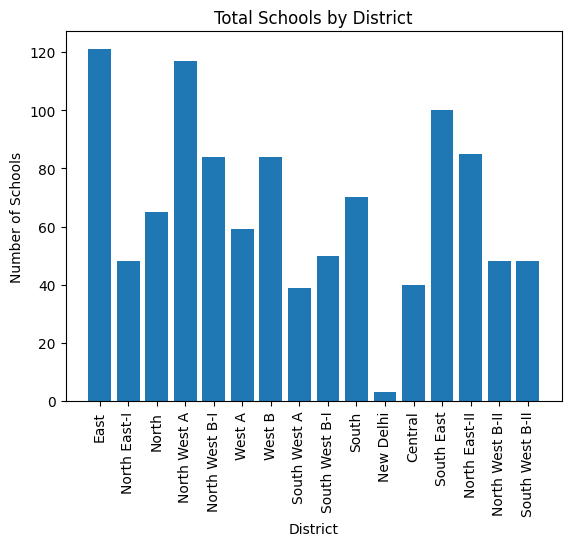

In [32]:
# Q10. Based on at least three visualizations, identify three important observations about the education system represented by this dataset.
import matplotlib.pyplot as plt

plt.bar(data["District"], data["No of Schools - Total"])
plt.xticks(rotation=90)
plt.xlabel("District")
plt.ylabel("Number of Schools")
plt.title("Total Schools by District")
plt.show()

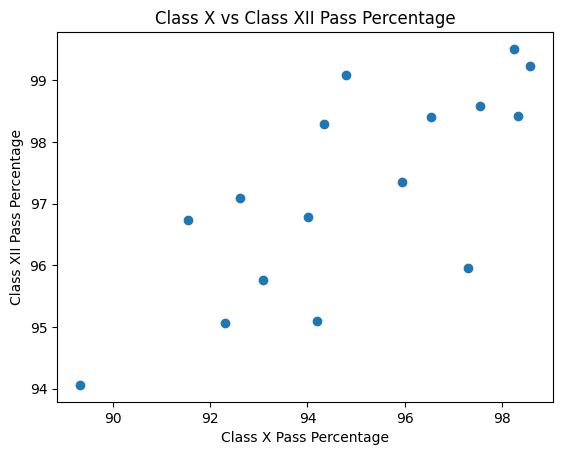

In [33]:
plt.scatter(
    data[" PASS PERCENTAGE IN CLASS X - \n(Before Compt.) - 2023-24"],
    data["PASS PERCENTAGE IN CLASS XII - (Before Compt.) - 2023-24"]
)

plt.xlabel("Class X Pass Percentage")
plt.ylabel("Class XII Pass Percentage")
plt.title("Class X vs Class XII Pass Percentage")
plt.show()

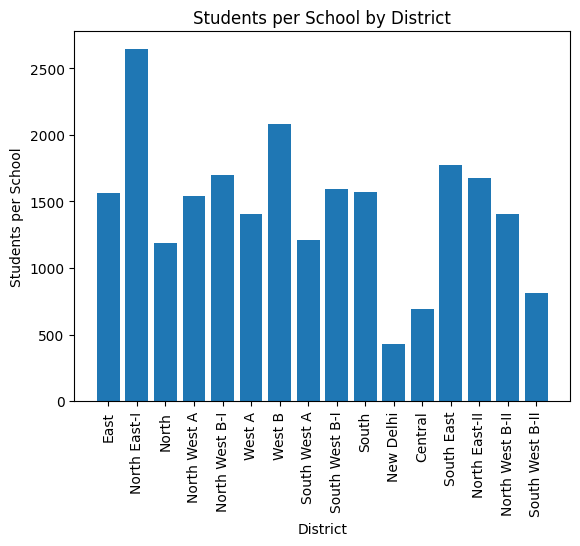

In [34]:
plt.bar(data["District"], data["Students per School"])
plt.xticks(rotation=90)
plt.xlabel("District")
plt.ylabel("Students per School")
plt.title("Students per School by District")
plt.show()